In [150]:
!pip install networkx

In [151]:
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd


In [152]:
import json

In [153]:
with open("api_troll_farm.json", encoding="utf-8") as f:
  data = json.load(f)

df = pd.json_normalize(data)
df['account_id'] = df['account_id'].str.lower()
display(df)

,account_id,metadata.last_ip,metadata.payment_hash,activity.retweets,metadata,activity
0,troll_bot_1,104.28.19.112,VISA-4455-XXXX-9090,"[real_user_11, TROLL_BOT_1, TROLL_BOT_1]",NaN,NaN
1,real_user_14,189.168.1.196,MC-8573-XXXX-1111,"[real_user_15, real_user_11]",NaN,NaN
2,real_user_13,189.168.1.184,None,"[real_user_3, real_user_9]",NaN,NaN
3,troll_bot_5,104.28.19.112,VISA-4455-XXXX-9090,"[real_user_12, TROLL_BOT_1, TROLL_BOT_5]",NaN,NaN
4,real_user_12,189.168.1.51,MC-4432-XXXX-1111,"[real_user_12, real_user_15]",NaN,NaN
5,real_user_11,189.168.1.231,MC-5554-XXXX-1111,"[real_user_14, real_user_6]",NaN,NaN
6,real_user_15,189.168.1.186,None,"[real_user_14, real_user_13]",NaN,NaN
7,real_user_8,189.168.1.246,MC-5803-XXXX-1111,"[real_user_10, real_user_15]",NaN,NaN
8,real_user_10,189.168.1.68,None,"[real_user_14, real_user_4]",NaN,NaN
9,troll_bot_1,104.28.19.112,VISA-4455-XXXX-9090,[real_user_2],NaN,NaN


#### FASE 1: Data Engineering

In [154]:
filas = []

# zip() recorre ambas columnas fila por fila al mismo tiempo
for origin, retweets in zip(df['account_id'], df['activity.retweets']):
  # Verificar que retweets sea una lista válida
  if isinstance(retweets, list):
    for retweet in retweets:
      retweet = retweet.lower()
      if origin != retweet:
        filas.append({
            'Origen': origin,
            'Destino': retweet,
            'Relacion': 'Retweet',
        })

df_rt = pd.DataFrame(filas).drop_duplicates()

In [155]:
display(df_rt)

,Origen,Destino,Relacion
0,troll_bot_1,real_user_11,Retweet
1,real_user_14,real_user_15,Retweet
2,real_user_14,real_user_11,Retweet
3,real_user_13,real_user_3,Retweet
4,real_user_13,real_user_9,Retweet
5,troll_bot_5,real_user_12,Retweet
6,troll_bot_5,troll_bot_1,Retweet
7,real_user_12,real_user_15,Retweet
8,real_user_11,real_user_14,Retweet
9,real_user_11,real_user_6,Retweet


In [156]:
filas_met = []

for cuenta in data:
  meta = cuenta.get('metadata') or {}
  filas_met.append({
      "usuario": cuenta['account_id'].lower(),
      "ip": meta.get('last_ip'),
      'tarjeta': meta.get('payment_hash'),
  })

df_meta = pd.DataFrame(filas_met).drop_duplicates()


In [157]:
display(df_meta)

,usuario,ip,tarjeta
0,troll_bot_1,104.28.19.112,VISA-4455-XXXX-9090
1,real_user_14,189.168.1.196,MC-8573-XXXX-1111
2,real_user_13,189.168.1.184,None
3,troll_bot_5,104.28.19.112,VISA-4455-XXXX-9090
4,real_user_12,189.168.1.51,MC-4432-XXXX-1111
5,real_user_11,189.168.1.231,MC-5554-XXXX-1111
6,real_user_15,189.168.1.186,None
7,real_user_8,189.168.1.246,MC-5803-XXXX-1111
8,real_user_10,189.168.1.68,None
10,troll_bot_4,104.28.19.112,VISA-4455-XXXX-9090


In [158]:
df_tarjeta = df_meta.dropna(subset=['tarjeta'])[["usuario", "tarjeta"]].drop_duplicates()

In [159]:
display(df_tarjeta)

,usuario,tarjeta
0,troll_bot_1,VISA-4455-XXXX-9090
1,real_user_14,MC-8573-XXXX-1111
3,troll_bot_5,VISA-4455-XXXX-9090
4,real_user_12,MC-4432-XXXX-1111
5,real_user_11,MC-5554-XXXX-1111
7,real_user_8,MC-5803-XXXX-1111
10,troll_bot_4,VISA-4455-XXXX-9090
11,troll_bot_6,VISA-4455-XXXX-9090
12,real_user_6,MC-2584-XXXX-1111
13,real_user_4,MC-1106-XXXX-1111


In [160]:
same_card = df_tarjeta.merge(df_tarjeta, on='tarjeta')

In [161]:
display(same_card)

,usuario_x,tarjeta,usuario_y
0,troll_bot_1,VISA-4455-XXXX-9090,troll_bot_1
1,troll_bot_1,VISA-4455-XXXX-9090,troll_bot_5
2,troll_bot_1,VISA-4455-XXXX-9090,troll_bot_4
3,troll_bot_1,VISA-4455-XXXX-9090,troll_bot_6
4,troll_bot_1,VISA-4455-XXXX-9090,troll_bot_3
5,troll_bot_1,VISA-4455-XXXX-9090,troll_bot_2
6,real_user_14,MC-8573-XXXX-1111,real_user_14
7,troll_bot_5,VISA-4455-XXXX-9090,troll_bot_1
8,troll_bot_5,VISA-4455-XXXX-9090,troll_bot_5
9,troll_bot_5,VISA-4455-XXXX-9090,troll_bot_4


In [162]:
same_card = same_card[same_card['usuario_x'] < same_card['usuario_y']]

df_tarjeta = pd.DataFrame({
    'Origen': same_card['usuario_x'],
    'Destino': same_card['usuario_y'],
    'Relacion': 'Misma_tarjeta'
})

In [163]:
display(df_tarjeta)

,Origen,Destino,Relacion
1,troll_bot_1,troll_bot_5,Misma_tarjeta
2,troll_bot_1,troll_bot_4,Misma_tarjeta
3,troll_bot_1,troll_bot_6,Misma_tarjeta
4,troll_bot_1,troll_bot_3,Misma_tarjeta
5,troll_bot_1,troll_bot_2,Misma_tarjeta
10,troll_bot_5,troll_bot_6,Misma_tarjeta
17,troll_bot_4,troll_bot_5,Misma_tarjeta
19,troll_bot_4,troll_bot_6,Misma_tarjeta
32,troll_bot_3,troll_bot_5,Misma_tarjeta
33,troll_bot_3,troll_bot_4,Misma_tarjeta


In [164]:
df_maestra = pd.concat([df_rt, df_tarjeta], ignore_index=True).drop_duplicates().reset_index(drop=True)

In [165]:
display(df_maestra)

,Origen,Destino,Relacion
0,troll_bot_1,real_user_11,Retweet
1,real_user_14,real_user_15,Retweet
2,real_user_14,real_user_11,Retweet
3,real_user_13,real_user_3,Retweet
4,real_user_13,real_user_9,Retweet
5,troll_bot_5,real_user_12,Retweet
6,troll_bot_5,troll_bot_1,Retweet
7,real_user_12,real_user_15,Retweet
8,real_user_11,real_user_14,Retweet
9,real_user_11,real_user_6,Retweet


### Fase 2: El grafo Multicapa

In [166]:
MG =nx.from_pandas_edgelist(df_maestra, 'Origen', 'Destino', 'Relacion', create_using=nx.MultiDiGraph())

print("\nNodos totales:", MG.number_of_nodes())
print("Aristas totales:", MG.number_of_edges())


Nodos totales: 21
Aristas totales: 52


In [167]:
display(MG['troll_bot_3']['troll_bot_5'])

AtlasView({0: {'Relacion': 'Misma_tarjeta'}})

### Fase 3: El Slicing

In [168]:
mt = [(u, v) for u, v, d in MG.edges(data=True) if d['Relacion'] == 'Misma_tarjeta']
G_equal = nx.Graph()
G_equal.add_nodes_from(MG.nodes())
G_equal.add_edges_from(mt)



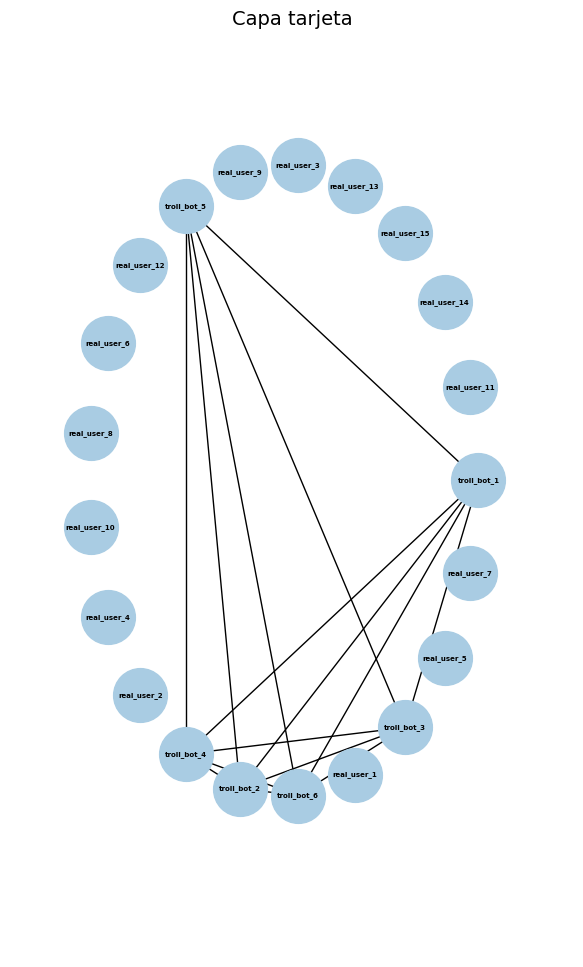

In [178]:

pos_fija = nx.circular_layout(MG)

plt.figure(figsize=(16, 12))

plt.subplot(1, 2, 1)
# Usamos la 'pos_fija' y ajustamos márgenes para que los nodos no se corten en los bordes
nx.draw(G_equal, pos_fija, with_labels=True, node_color='#A9CCE3', node_size=1500, font_weight='bold', font_size=5)
plt.title('Capa tarjeta', fontsize=14)
plt.margins(0.2) # Da un 20% de espacio extra en los bordes

In [179]:
components = list(nx.connected_components(G_equal))

In [180]:
display(components)

[{'troll_bot_1',
  'troll_bot_2',
  'troll_bot_3',
  'troll_bot_4',
  'troll_bot_5',
  'troll_bot_6'},
 {'real_user_11'},
 {'real_user_14'},
 {'real_user_15'},
 {'real_user_13'},
 {'real_user_3'},
 {'real_user_9'},
 {'real_user_12'},
 {'real_user_6'},
 {'real_user_8'},
 {'real_user_10'},
 {'real_user_4'},
 {'real_user_2'},
 {'real_user_1'},
 {'real_user_5'},
 {'real_user_7'}]

### El veredicto

1. ¿Cuáles son los nombres exactos (account_id) de los bots que conforman el anillo de fraude?


> {'troll_bot_1',
  'troll_bot_2',
  'troll_bot_3',
  'troll_bot_4',
  'troll_bot_5',
  'troll_bot_6'}

2. ¿Cuál es el Hash de la tarjeta de crédito comprometida que el equipo de soporte técnico debe bloquear ahora mismo?


> VISA-4455-XXXX-9090


3. Si tuvieran que entrenar un modelo de predicción, ¿cómo le pasarían este descubrimiento al modelo tabular (La matriz X de entrenamiento)?


> Lo que encontramos en el grafo se convierte en nuevas columnas de la matriz X, una fila por usuario. Por ejemplo:

> en_anillo_fraude: vale 1 si la cuenta comparte tarjeta con otras cuentas y 0 si no.

> cuentas_misma_tarjeta: cuántas cuentas usan su misma tarjeta (6 para los bots, 1 para un usuario normal).

> El modelo recibe el patrón del grafo como números y puede aprender que compartir tarjeta con muchas cuentas = fraude.

